In [2]:
import numpy as np
import pandas as pd
import os

file_path = os.path.abspath("..\\Dataset\\laptop_data.csv")
df = pd.read_csv(file_path)

In [7]:
df.head(3)

,Unnamed: 0,Company,TypeName,Inches,ScreenResolution,Cpu,Ram,Memory,Gpu,OpSys,Weight,Price
0,0,Apple,Ultrabook,13.3,IPS Panel Retina Display 2560x1600,Intel Core i5 2.3GHz,8GB,128GB SSD,Intel Iris Plus Graphics 640,macOS,1.37kg,71378.6832
1,1,Apple,Ultrabook,13.3,1440x900,Intel Core i5 1.8GHz,8GB,128GB Flash Storage,Intel HD Graphics 6000,macOS,1.34kg,47895.5232
2,2,HP,Notebook,15.6,Full HD 1920x1080,Intel Core i5 7200U 2.5GHz,8GB,256GB SSD,Intel HD Graphics 620,No OS,1.86kg,30636.0000


In [8]:
df = df.drop(columns="Unnamed: 0")

In [9]:
df.shape # 11 Features and 1303 instances

(1303, 11)

In [10]:
df.isnull().sum() # no null value exists

Company             0
TypeName            0
Inches              0
ScreenResolution    0
Cpu                 0
Ram                 0
Memory              0
Gpu                 0
OpSys               0
Weight              0
Price               0
dtype: int64

In [11]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1303 entries, 0 to 1302
Data columns (total 11 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   Company           1303 non-null   object 
 1   TypeName          1303 non-null   object 
 2   Inches            1303 non-null   float64
 3   ScreenResolution  1303 non-null   object 
 4   Cpu               1303 non-null   object 
 5   Ram               1303 non-null   object 
 6   Memory            1303 non-null   object 
 7   Gpu               1303 non-null   object 
 8   OpSys             1303 non-null   object 
 9   Weight            1303 non-null   object 
 10  Price             1303 non-null   float64
dtypes: float64(2), object(9)
memory usage: 112.1+ KB


In [12]:
df.describe()

,Inches,Price
count,1303.000000,1303.000000
mean,15.017191,59870.042910
std,1.426304,37243.201786
min,10.100000,9270.720000
25%,14.000000,31914.720000
50%,15.600000,52054.560000
75%,15.600000,79274.246400
max,18.400000,324954.720000


In [13]:
df.duplicated().sum() # it says 29 instances are duplicated

np.int64(29)

In [14]:
df[df.duplicated()] # We can see there is still difference exists while it is considered as duplicated

,Company,TypeName,Inches,ScreenResolution,Cpu,Ram,Memory,Gpu,OpSys,Weight,Price
1274,Asus,Notebook,15.6,1366x768,Intel Celeron Dual Core N3050 1.6GHz,4GB,500GB HDD,Intel HD Graphics,Windows 10,2.2kg,19660.3200
1275,Asus,Ultrabook,13.3,IPS Panel Full HD 1920x1080,Intel Core M 6Y30 0.9GHz,8GB,512GB SSD,Intel HD Graphics 515,Windows 10,1.2kg,38841.1200
1276,Dell,Notebook,15.6,1366x768,Intel Core i3 7100U 2.4GHz,6GB,1TB HDD,Intel HD Graphics 620,Windows 10,2.3kg,24455.5200
1277,Acer,Notebook,15.6,1366x768,Intel Celeron Dual Core N3060 1.6GHz,4GB,500GB HDD,Intel HD Graphics 400,Linux,2.4kg,15397.9200
1278,Dell,Notebook,15.6,1366x768,Intel Celeron Dual Core N3050 1.6GHz,2GB,500GB HDD,Intel HD Graphics,Windows 10,2.20kg,20193.1200
1279,Lenovo,Notebook,15.6,IPS Panel Full HD 1920x1080,Intel Core i7 6700HQ 2.6GHz,8GB,1TB HDD,Nvidia GeForce GTX 960M,Windows 10,2.6kg,47898.7200
1280,HP,Notebook,15.6,Full HD 1920x1080,AMD A9-Series 9410 2.9GHz,6GB,1.0TB Hybrid,AMD Radeon R7 M440,Windows 10,2.04kg,29303.4672
1281,Dell,Notebook,15.6,1366x768,Intel Core i7 7500U 2.7GHz,8GB,1TB HDD,AMD Radeon R5 M430,Linux,2.3kg,42943.1472
1282,HP,Netbook,11.6,1366x768,Intel Celeron Dual Core N3060 1.6GHz,2GB,32GB Flash Storage,Intel HD Graphics 400,Windows 10,1.17kg,11135.5200
1283,Asus,Notebook,15.6,1366x768,Intel Core i7 6500U 2.5GHz,4GB,500GB HDD,Nvidia GeForce 920M,Windows 10,2.2kg,38378.6496


Text(0.5, 1.0, 'Distribution of Prices')

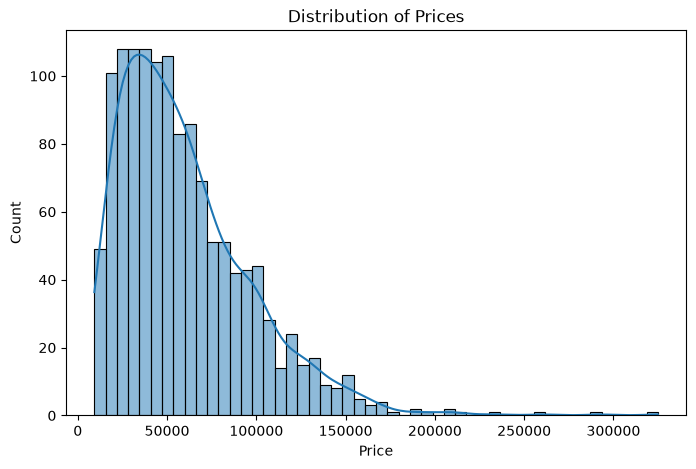

In [15]:
import matplotlib.pyplot as plt 
import seaborn as sns 

plt.figure(figsize=(8,5))
sns.histplot(df.Price,bins=50,kde=True)
plt.title("Distribution of Prices")


As we can see that there is a single peak and it is right skewed so we can use log(Price) to bell-shape this distribution

Text(0.5, 1.0, 'Distribution of Prices')

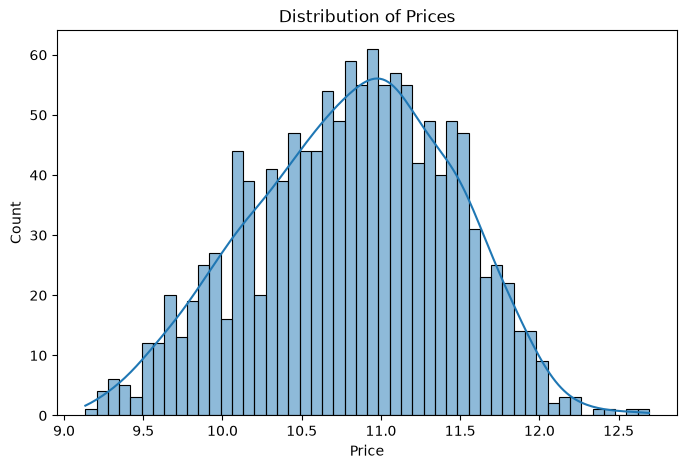

In [16]:
df['Price'] = np.log(df['Price'])
plt.figure(figsize=(8,5))
sns.histplot(df.Price,bins=50,kde=True) # Now the data is centralized
plt.title("Distribution of Prices")

Text(0.5, 1.0, 'Price Outliers')

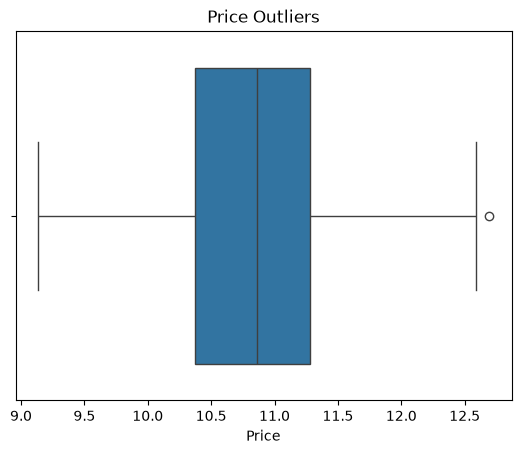

In [17]:
sns.boxplot(x=df['Price'])
plt.title("Price Outliers")

In [18]:
outliers = df[df.Price > 12.5] # Outliers or Exceptions 

In [19]:
outliers # Since we transformed data already in log form the values difference are much closer ( this might help reduce error and improve model score )

,Company,TypeName,Inches,ScreenResolution,Cpu,Ram,Memory,Gpu,OpSys,Weight,Price
196,Razer,Gaming,17.3,4K Ultra HD / Touchscreen 3840x2160,Intel Core i7 7820HK 2.9GHz,32GB,1TB SSD,Nvidia GeForce GTX 1080,Windows 10,3.49kg,12.691441
830,Razer,Gaming,17.3,4K Ultra HD / Touchscreen 3840x2160,Intel Core i7 7820HK 2.9GHz,32GB,512GB SSD,Nvidia GeForce GTX 1080,Windows 10,3.49kg,12.587883


<Axes: >

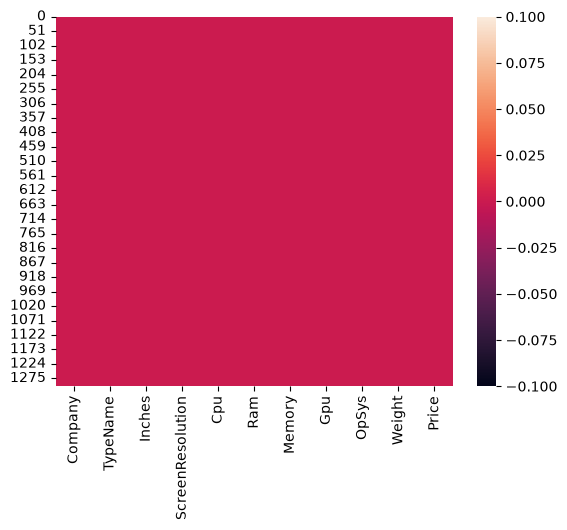

In [20]:
sns.heatmap(df.isnull())

Hence no missing values exists in the dataset

In [21]:
# Converting to Numeric Values
df['Ram_(GB)'] = df['Ram'].str.replace("GB","", case=False).str.strip()
df['Ram_(GB)'] = pd.to_numeric(df["Ram_(GB)"])

df['Weight_(kg)'] = df['Weight'].str.replace("kg", "", case=False).str.strip()
df['Weight_(kg)'] = pd.to_numeric(df['Weight_(kg)'])

# df['Memory'] = df["Memory"].str.replace("GB","",case=False).str.strip()
# df[["Memory_Size","Memory_Type"]] = df["Memory"].str.extract(r'(\d+)\s*([a-zA-Z]+)') # To catch every Character After number Until a space occurs
# df[["Memory_Size_(GB)","Memory_Type"]] = df["Memory"].str.extract(r'(\d+)\s*(.*)') # Takes in everything after the numeric values end
# df["Memory_Type_To_Clean"] = df["Memory_Type"].str.strip() # Cleans Up Surrounding white spaces 
# df['Memory_Size_(GB)'] = pd.to_numeric(df['Memory_Size_(GB)'])


In [22]:
# df = df.drop(columns=['Ram','Weight','Memory']) # Values are converted now can drop these features as we dont need extra columns

In [23]:
df.head(3)

,Company,TypeName,Inches,ScreenResolution,Cpu,Ram,Memory,Gpu,OpSys,Weight,Price,Ram_(GB),Weight_(kg)
0,Apple,Ultrabook,13.3,IPS Panel Retina Display 2560x1600,Intel Core i5 2.3GHz,8GB,128GB SSD,Intel Iris Plus Graphics 640,macOS,1.37kg,11.175755,8,1.37
1,Apple,Ultrabook,13.3,1440x900,Intel Core i5 1.8GHz,8GB,128GB Flash Storage,Intel HD Graphics 6000,macOS,1.34kg,10.776777,8,1.34
2,HP,Notebook,15.6,Full HD 1920x1080,Intel Core i5 7200U 2.5GHz,8GB,256GB SSD,Intel HD Graphics 620,No OS,1.86kg,10.329931,8,1.86


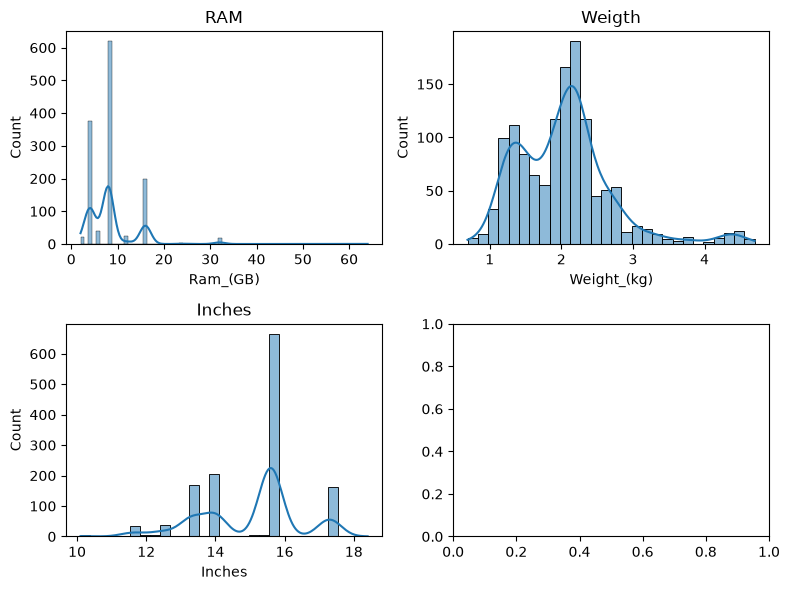

In [24]:
num_cols = ['Ram_(GB)','Weight_(kg)','Inches','Memory_Size_(GB)']
fig, axes = plt.subplots(nrows=2,ncols=2,figsize=(8,6))

sns.histplot(df['Ram_(GB)'], ax=axes[0, 0],kde=True)
axes[0, 0].set_title('RAM')
sns.histplot(df['Weight_(kg)'], ax=axes[0, 1],kde=True)
axes[0, 1].set_title('Weigth')
sns.histplot(df['Inches'], ax=axes[1, 0],kde=True)
axes[1, 0].set_title('Inches')
# sns.histplot(df['Memory_Size_(GB)'], ax=axes[1, 1],kde=True)
# axes[1, 1].set_title('Memory_Size')
plt.tight_layout()

Here the data have multiple peaks because for every segment of Laptops there are fixed sizes of Ram,Memory etc so it is normal and transforming these values may create misunderstanding or wrong predictions

<Axes: >

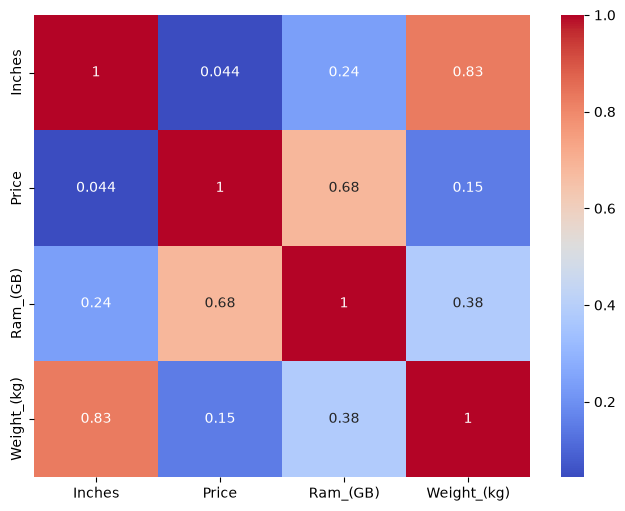

In [25]:
corr = df.corr(numeric_only=True)
plt.figure(figsize=(8,6))
sns.heatmap(corr,
            annot=True,
            cmap='coolwarm')

Ram and Price Have a high correlation, <br>
Inches and Weight are also corelated

<Axes: xlabel='Company', ylabel='Price'>

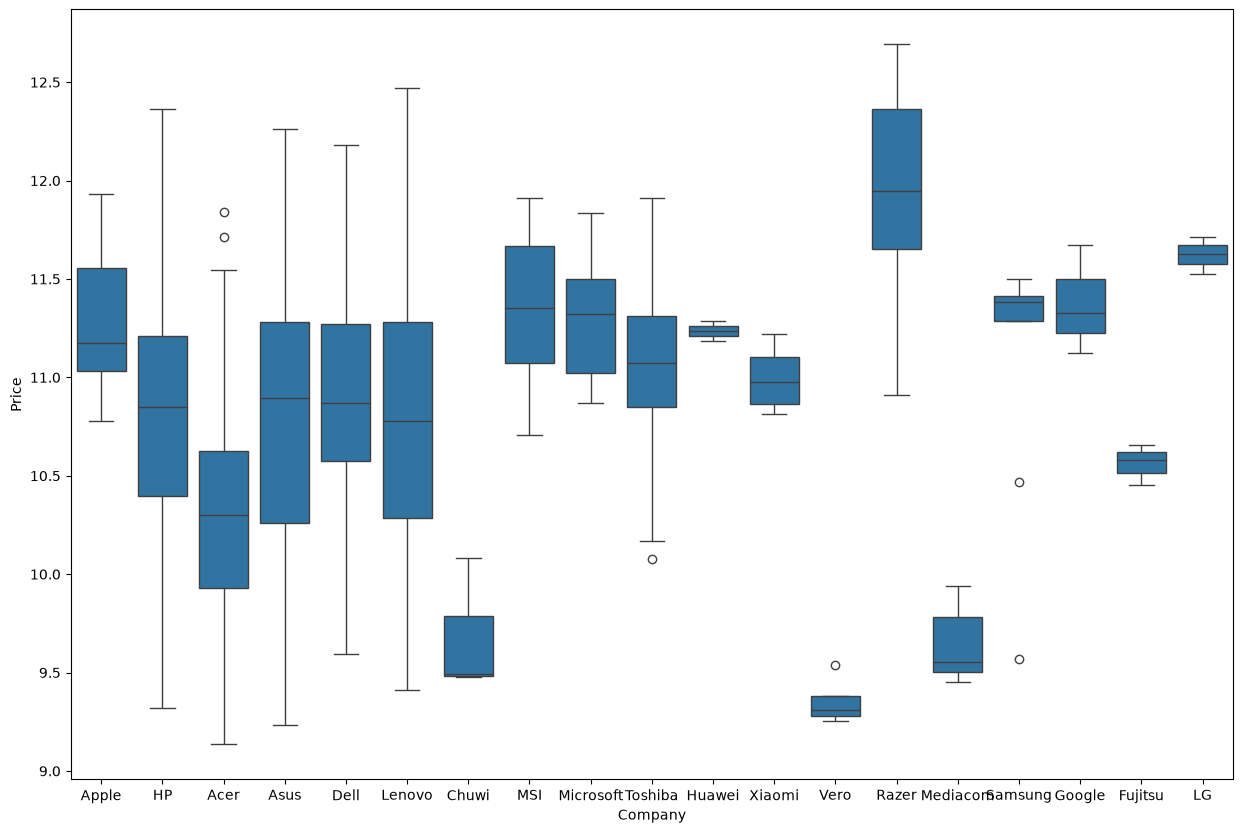

In [26]:
plt.figure(figsize=(15,10))
sns.boxplot(df,x='Company',y='Price')

<Axes: xlabel='TypeName', ylabel='Price'>

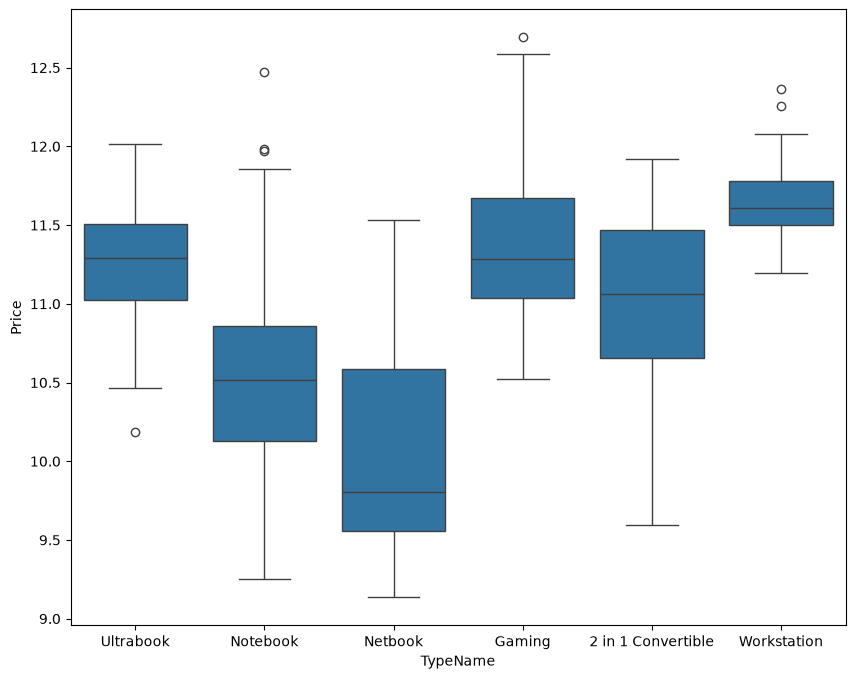

In [27]:
plt.figure(figsize=(10,8))
sns.boxplot(data=df,x='TypeName',y='Price')

<Axes: xlabel='Ram_(GB)', ylabel='Price'>

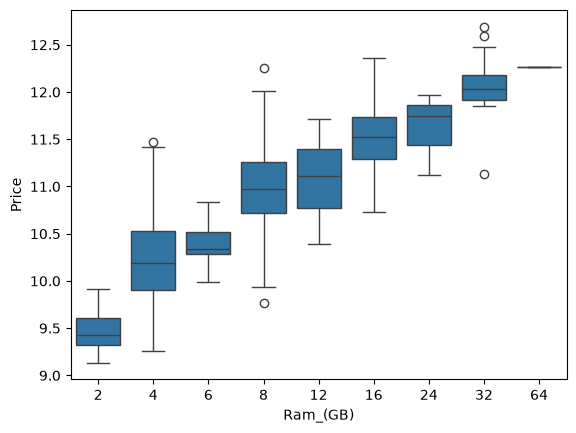

In [28]:
sns.boxplot(
    x='Ram_(GB)',
    y='Price',
    data=df
)

<Axes: xlabel='Weight_(kg)', ylabel='Price'>

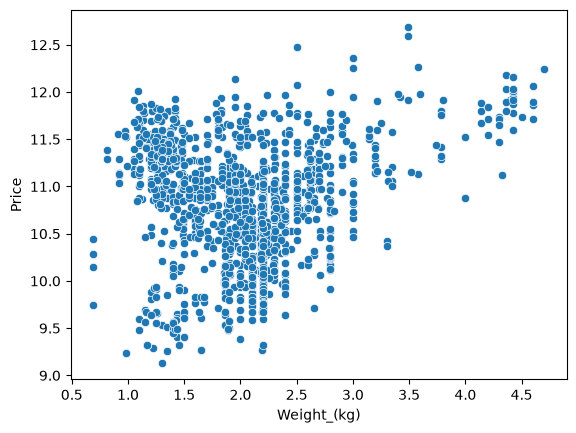

In [29]:
sns.scatterplot(
    x='Weight_(kg)',
    y='Price',
    data=df
)

<Axes: xlabel='Inches', ylabel='Price'>

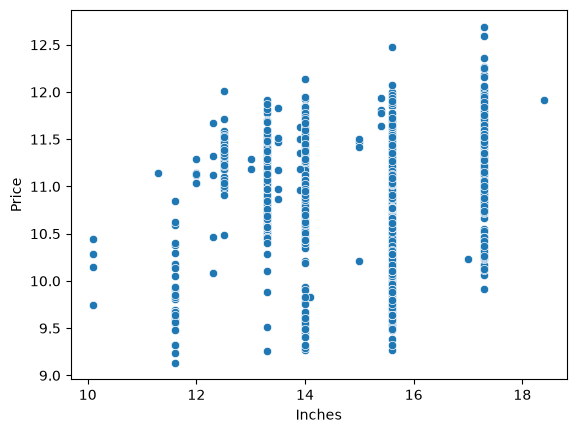

In [30]:
sns.scatterplot(
    x='Inches',
    y='Price',
    data=df
)

In [31]:
df.TypeName.value_counts()

TypeName
Notebook              727
Gaming                205
Ultrabook             196
2 in 1 Convertible    121
Workstation            29
Netbook                25
Name: count, dtype: int64

In [32]:
df.Company.value_counts()

Company
Dell         297
Lenovo       297
HP           274
Asus         158
Acer         103
MSI           54
Toshiba       48
Apple         21
Samsung        9
Mediacom       7
Razer          7
Microsoft      6
Vero           4
Xiaomi         4
Chuwi          3
Fujitsu        3
Google         3
LG             3
Huawei         2
Name: count, dtype: int64

In [33]:
df.OpSys.value_counts()

OpSys
Windows 10      1072
No OS             66
Linux             62
Windows 7         45
Chrome OS         27
macOS             13
Mac OS X           8
Windows 10 S       8
Android            2
Name: count, dtype: int64

In [34]:
def map_os(os):
    if 'Windows' in os:
        return 'Windows'
    elif 'macOS' in os or 'Mac OS X' in os:
        return 'macOS'
    elif 'Linux' in os:
        return 'Linux'
    else:
        return 'Other/No OS'
df['OpSys_Grouped'] = df['OpSys'].apply(map_os)

Thought of making this simplistic so just took the companies of CPU


In [35]:
df['Cpu_Company']=df.Cpu.str.extract(r'(^\w+)')

In [36]:
df['Cpu_Company'].value_counts()

Cpu_Company
Intel      1240
AMD          62
Samsung       1
Name: count, dtype: int64

Similar for GPU

In [37]:
df['Gpu_Grouped'] = df.Gpu.str.extract(r'(^\w+)')

In [38]:
df['Gpu_Grouped'].value_counts()

Gpu_Grouped
Intel     722
Nvidia    400
AMD       180
ARM         1
Name: count, dtype: int64

*To get the ppi we need Height and Width of the Screen*

In [39]:
df[['Screen_Height','Screen_Width']] = df['ScreenResolution'].str.extract(r'(\d+)x(\d+)').astype(int)

In [40]:
df['ScreenType'] = df['ScreenResolution'].str.extract(r'^(.*?)\s*\d+x\d+')[0].str.strip()

In [41]:
df = df.drop(columns='ScreenResolution')

In [42]:
df['PPI'] = (np.sqrt(
    (df['Screen_Height']**2) + 
    (df['Screen_Width']**2))
    / df['Inches']) 

In [43]:
# df[df['Memory_Type'] == '.0TB Hybrid']

In [44]:
df['Memory'].value_counts()

Memory
256GB SSD                        412
1TB HDD                          223
500GB HDD                        132
512GB SSD                        118
128GB SSD +  1TB HDD              94
128GB SSD                         76
256GB SSD +  1TB HDD              73
32GB Flash Storage                38
2TB HDD                           16
64GB Flash Storage                15
1TB SSD                           14
512GB SSD +  1TB HDD              14
256GB SSD +  2TB HDD              10
1.0TB Hybrid                       9
256GB Flash Storage                8
16GB Flash Storage                 7
32GB SSD                           6
180GB SSD                          5
128GB Flash Storage                4
16GB SSD                           3
512GB SSD +  2TB HDD               3
128GB SSD +  2TB HDD               2
256GB SSD +  256GB SSD             2
512GB Flash Storage                2
1TB SSD +  1TB HDD                 2
256GB SSD +  500GB HDD             2
64GB SSD                       

In [ ]:
# Replace '1TB' or '1.0TB' with '1000GB' / '2TB' with '2000GB'
df['Memory_clean'] = df['Memory'].astype(str)
df['Memory_clean'] = df['Memory_clean'].str.replace(r'(\d+\.?\d*)\s*TB', lambda m: f"{int(float(m.group(1)) * 1000)}GB", regex=True) # 1000 is for rough estimate it is not true value

# Split primary drive and secondary drive (separated by '+')
df_split = df['Memory_clean'].str.split('+', expand=True)
primary = df_split[0].str.strip()
secondary = df_split[1].str.strip().fillna('')

def get_capacity(series, drive_type):
    pattern = rf'(?i)(\d+)\s*GB.*\b{drive_type}\b' # (?i) makes the regex pattern case-insensitive
    return series.str.extract(pattern)[0].fillna(0).astype(int)

# Extract storage capacities using (?i) inside regex for case-insensitivity
df['SSD_GB'] = get_capacity(primary, 'SSD') + get_capacity(secondary, 'SSD')
df['HDD_GB'] = get_capacity(primary, 'HDD') + get_capacity(secondary, 'HDD')
df['Flash_GB'] = get_capacity(primary, 'Flash Storage') + get_capacity(secondary, 'Flash Storage')
df['Hybrid_GB'] = get_capacity(primary, 'Hybrid') + get_capacity(secondary, 'Hybrid')

df['Total_Storage_GB'] = df['SSD_GB'] + df['HDD_GB'] + df['Flash_GB'] + df['Hybrid_GB'] # Total Storage Capacity

C:\Users\TeReX\AppData\Local\Temp\ipykernel_24092\2350664494.py:14: FutureWarning: Downcasting object dtype arrays on .fillna, .ffill, .bfill is deprecated and will change in a future version. Call result.infer_objects(copy=False) instead. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`
  return series.str.extract(pattern)[0].fillna(0).astype(int)


In [ ]:
df['IPS'] = df['ScreenType'].str.contains('IPS', case=False).astype(int) #if screentype contains IPS it returns 1 else 0

df['Touchscreen'] = df['ScreenType'].str.contains('Touchscreen', case=False).astype(int) # similaryly for touchscreen

def get_screen_quality(text):
    text = str(text)
    if '4K' in text or 'Retina' in text:
        return '4K/Retina'
    elif 'Quad HD+' in text or 'QHD' in text:
        return 'Quad HD+'
    elif 'Full HD' in text:
        return 'Full HD'
    else:
        return 'Standard HD'

df['Screen_Quality'] = df['ScreenType'].apply(get_screen_quality)

In [47]:
df.columns

Index(['Company', 'TypeName', 'Inches', 'Cpu', 'Ram', 'Memory', 'Gpu', 'OpSys',
       'Weight', 'Price', 'Ram_(GB)', 'Weight_(kg)', 'OpSys_Grouped',
       'Cpu_Company', 'Gpu_Grouped', 'Screen_Height', 'Screen_Width',
       'ScreenType', 'PPI', 'Memory_clean', 'SSD_GB', 'HDD_GB', 'Flash_GB',
       'Hybrid_GB', 'Total_Storage_GB', 'IPS', 'Touchscreen',
       'Screen_Quality'],
      dtype='object')

In [48]:
df.shape

(1303, 28)

## **Encoding**

In [49]:
df_Company = df[['Company']]
from sklearn.preprocessing import OneHotEncoder
Encoder = OneHotEncoder(handle_unknown='ignore',sparse_output=False)
df_comp_encoded = Encoder.fit_transform(df_Company)
df_comp_encoded = pd.DataFrame(data=df_comp_encoded,columns=Encoder.get_feature_names_out(['Company']),index=df.index).astype(int)
df_comp_encoded


,Company_Acer,Company_Apple,Company_Asus,Company_Chuwi,Company_Dell,Company_Fujitsu,Company_Google,Company_HP,Company_Huawei,Company_LG,Company_Lenovo,Company_MSI,Company_Mediacom,Company_Microsoft,Company_Razer,Company_Samsung,Company_Toshiba,Company_Vero,Company_Xiaomi
0,0,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0
1,0,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0
2,0,0,0,0,0,0,0,1,0,0,0,0,0,0,0,0,0,0,0
3,0,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0
4,0,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
1298,0,0,0,0,0,0,0,0,0,0,1,0,0,0,0,0,0,0,0
1299,0,0,0,0,0,0,0,0,0,0,1,0,0,0,0,0,0,0,0
1300,0,0,0,0,0,0,0,0,0,0,1,0,0,0,0,0,0,0,0
1301,0,0,0,0,0,0,0,1,0,0,0,0,0,0,0,0,0,0,0


In [50]:
df_TypeName = df[['TypeName']]
df_TypeName_encoded = Encoder.fit_transform(df_TypeName)
df_TypeName_encoded = pd.DataFrame(df_TypeName_encoded,columns=Encoder.get_feature_names_out(['TypeName']),index=df.index).astype(int)
df_TypeName_encoded

,TypeName_2 in 1 Convertible,TypeName_Gaming,TypeName_Netbook,TypeName_Notebook,TypeName_Ultrabook,TypeName_Workstation
0,0,0,0,0,1,0
1,0,0,0,0,1,0
2,0,0,0,1,0,0
3,0,0,0,0,1,0
4,0,0,0,0,1,0
...,...,...,...,...,...,...
1298,1,0,0,0,0,0
1299,1,0,0,0,0,0
1300,0,0,0,1,0,0
1301,0,0,0,1,0,0


In [51]:
df.columns

Index(['Company', 'TypeName', 'Inches', 'Cpu', 'Ram', 'Memory', 'Gpu', 'OpSys',
       'Weight', 'Price', 'Ram_(GB)', 'Weight_(kg)', 'OpSys_Grouped',
       'Cpu_Company', 'Gpu_Grouped', 'Screen_Height', 'Screen_Width',
       'ScreenType', 'PPI', 'Memory_clean', 'SSD_GB', 'HDD_GB', 'Flash_GB',
       'Hybrid_GB', 'Total_Storage_GB', 'IPS', 'Touchscreen',
       'Screen_Quality'],
      dtype='object')

In [52]:
df_OS = df[['OpSys_Grouped']]
df_OpSys_encoded = Encoder.fit_transform(df_OS)
df_OpSys_encoded = pd.DataFrame(df_OpSys_encoded,columns=Encoder.get_feature_names_out(['OpSys_Grouped']),index=df.index).astype(int)
df_OpSys_encoded

,OpSys_Grouped_Linux,OpSys_Grouped_Other/No OS,OpSys_Grouped_Windows,OpSys_Grouped_macOS
0,0,0,0,1
1,0,0,0,1
2,0,1,0,0
3,0,0,0,1
4,0,0,0,1
...,...,...,...,...
1298,0,0,1,0
1299,0,0,1,0
1300,0,0,1,0
1301,0,0,1,0


In [53]:
df_remain_encoded = pd.get_dummies(df,columns=['Cpu_Company','Gpu_Grouped'], drop_first=True) # Shorter Way of doing it 

In [54]:
df_encoded = pd.concat([df_comp_encoded ,df_TypeName_encoded , df_OpSys_encoded , df_remain_encoded],axis=1) # Cobining all encoded Data set

In [55]:
df_unscaled = df_encoded.copy() # All works done i guess

In [56]:
numeric_cols = df_encoded.select_dtypes(include=['int64','float64','bool']).columns
numeric_cols # Here We are seeking columns only

Index(['Company_Acer', 'Company_Apple', 'Company_Asus', 'Company_Chuwi',
       'Company_Dell', 'Company_Fujitsu', 'Company_Google', 'Company_HP',
       'Company_Huawei', 'Company_LG', 'Company_Lenovo', 'Company_MSI',
       'Company_Mediacom', 'Company_Microsoft', 'Company_Razer',
       'Company_Samsung', 'Company_Toshiba', 'Company_Vero', 'Company_Xiaomi',
       'TypeName_2 in 1 Convertible', 'TypeName_Gaming', 'TypeName_Netbook',
       'TypeName_Notebook', 'TypeName_Ultrabook', 'TypeName_Workstation',
       'OpSys_Grouped_Linux', 'OpSys_Grouped_Other/No OS',
       'OpSys_Grouped_Windows', 'OpSys_Grouped_macOS', 'Inches', 'Price',
       'Ram_(GB)', 'Weight_(kg)', 'Screen_Height', 'Screen_Width', 'PPI',
       'SSD_GB', 'HDD_GB', 'Flash_GB', 'Hybrid_GB', 'Total_Storage_GB', 'IPS',
       'Touchscreen', 'Cpu_Company_Intel', 'Cpu_Company_Samsung',
       'Gpu_Grouped_ARM', 'Gpu_Grouped_Intel', 'Gpu_Grouped_Nvidia'],
      dtype='object')

In [57]:
df_encoded = df_encoded.select_dtypes(include=['int64','float64','bool'])
df_encoded

,Company_Acer,Company_Apple,Company_Asus,Company_Chuwi,Company_Dell,Company_Fujitsu,Company_Google,Company_HP,Company_Huawei,Company_LG,...,Flash_GB,Hybrid_GB,Total_Storage_GB,IPS,Touchscreen,Cpu_Company_Intel,Cpu_Company_Samsung,Gpu_Grouped_ARM,Gpu_Grouped_Intel,Gpu_Grouped_Nvidia
0,0,1,0,0,0,0,0,0,0,0,...,0,0,128,1,0,True,False,False,True,False
1,0,1,0,0,0,0,0,0,0,0,...,128,0,128,0,0,True,False,False,True,False
2,0,0,0,0,0,0,0,1,0,0,...,0,0,256,0,0,True,False,False,True,False
3,0,1,0,0,0,0,0,0,0,0,...,0,0,512,1,0,True,False,False,False,False
4,0,1,0,0,0,0,0,0,0,0,...,0,0,256,1,0,True,False,False,True,False
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
1298,0,0,0,0,0,0,0,0,0,0,...,0,0,128,1,1,True,False,False,True,False
1299,0,0,0,0,0,0,0,0,0,0,...,0,0,512,1,1,True,False,False,True,False
1300,0,0,0,0,0,0,0,0,0,0,...,64,0,64,0,0,True,False,False,True,False
1301,0,0,0,0,0,0,0,1,0,0,...,0,0,1000,0,0,True,False,False,False,False


In [58]:
from sklearn.preprocessing import StandardScaler
scale = StandardScaler()
df_scaled = pd.DataFrame(scale.fit_transform(df_encoded),columns=numeric_cols,index=df.index)
df_scaled

,Company_Acer,Company_Apple,Company_Asus,Company_Chuwi,Company_Dell,Company_Fujitsu,Company_Google,Company_HP,Company_Huawei,Company_LG,...,Flash_GB,Hybrid_GB,Total_Storage_GB,IPS,Touchscreen,Cpu_Company_Intel,Cpu_Company_Samsung,Gpu_Grouped_ARM,Gpu_Grouped_Intel,Gpu_Grouped_Nvidia
0,-0.292973,7.813298,-0.371472,-0.048038,-0.543349,-0.048038,-0.048038,-0.516021,-0.039208,-0.048038,...,-0.150538,-0.095448,-1.033327,1.603079,-0.415713,0.225403,-0.027714,-0.027714,0.897056,-0.665558
1,-0.292973,7.813298,-0.371472,-0.048038,-0.543349,-0.048038,-0.048038,-0.516021,-0.039208,-0.048038,...,4.079124,-0.095448,-1.033327,-0.623799,-0.415713,0.225403,-0.027714,-0.027714,0.897056,-0.665558
2,-0.292973,-0.127987,-0.371472,-0.048038,-0.543349,-0.048038,-0.048038,1.937905,-0.039208,-0.048038,...,-0.150538,-0.095448,-0.759430,-0.623799,-0.415713,0.225403,-0.027714,-0.027714,0.897056,-0.665558
3,-0.292973,7.813298,-0.371472,-0.048038,-0.543349,-0.048038,-0.048038,-0.516021,-0.039208,-0.048038,...,-0.150538,-0.095448,-0.211637,1.603079,-0.415713,0.225403,-0.027714,-0.027714,-1.114758,-0.665558
4,-0.292973,7.813298,-0.371472,-0.048038,-0.543349,-0.048038,-0.048038,-0.516021,-0.039208,-0.048038,...,-0.150538,-0.095448,-0.759430,1.603079,-0.415713,0.225403,-0.027714,-0.027714,0.897056,-0.665558
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
1298,-0.292973,-0.127987,-0.371472,-0.048038,-0.543349,-0.048038,-0.048038,-0.516021,-0.039208,-0.048038,...,-0.150538,-0.095448,-1.033327,1.603079,2.405506,0.225403,-0.027714,-0.027714,0.897056,-0.665558
1299,-0.292973,-0.127987,-0.371472,-0.048038,-0.543349,-0.048038,-0.048038,-0.516021,-0.039208,-0.048038,...,-0.150538,-0.095448,-0.211637,1.603079,2.405506,0.225403,-0.027714,-0.027714,0.897056,-0.665558
1300,-0.292973,-0.127987,-0.371472,-0.048038,-0.543349,-0.048038,-0.048038,-0.516021,-0.039208,-0.048038,...,1.964293,-0.095448,-1.170275,-0.623799,-0.415713,0.225403,-0.027714,-0.027714,0.897056,-0.665558
1301,-0.292973,-0.127987,-0.371472,-0.048038,-0.543349,-0.048038,-0.048038,1.937905,-0.039208,-0.048038,...,-0.150538,-0.095448,0.832594,-0.623799,-0.415713,0.225403,-0.027714,-0.027714,-1.114758,-0.665558


In [60]:
from sklearn.model_selection import train_test_split

X = df_scaled.drop(columns=['Price'])
y = df_unscaled['Price']

X_train,X_test,y_train,y_test = train_test_split(X,y,test_size=0.2,random_state=42)

In [61]:
from sklearn.linear_model import LinearRegression
lr = LinearRegression()
lr.fit(X_train,y_train)

,"fit_intercept fit_intercept: bool, default=TrueWhether to calculate the intercept for this model. If setto False, no intercept will be used in calculations(i.e. data is expected to be centered).",True
,"copy_X copy_X: bool, default=TrueIf True, X will be copied; else, it may be overwritten.",True
,"tol tol: float, default=1e-6The precision of the solution (`coef_`) is determined by `tol` whichspecifies a different convergence criterion for the `lsqr` solver.`tol` is set as `atol` and `btol` of :func:`scipy.sparse.linalg.lsqr` whenfitting on sparse training data. This parameter has no effect when fittingon dense data... versionadded:: 1.7",1e-06
,"n_jobs n_jobs: int, default=NoneThe number of jobs to use for the computation. This will only providespeedup in case of sufficiently large problems, that is if firstly`n_targets > 1` and secondly `X` is sparse or if `positive` is setto `True`. ``None`` means 1 unless in a:obj:`joblib.parallel_backend` context. ``-1`` means using allprocessors. See :term:`Glossary ` for more details.",None
,"positive positive: bool, default=FalseWhen set to ``True``, forces the coefficients to be positive. Thisoption is only supported for dense arrays.For a comparison between a linear regression model with positive constraintson the regression coefficients and a linear regression without such constraints,see :ref:`sphx_glr_auto_examples_linear_model_plot_nnls.py`... versionadded:: 0.24",False


In [62]:
from sklearn.ensemble import RandomForestRegressor
rnd_foe = RandomForestRegressor(random_state=42,n_estimators=150)
rnd_foe.fit(X_train,y_train)

,"n_estimators n_estimators: int, default=100The number of trees in the forest... versionchanged:: 0.22 The default value of ``n_estimators`` changed from 10 to 100 in 0.22.",150
,"criterion criterion: {""squared_error"", ""absolute_error"", ""friedman_mse"", ""poisson""}, default=""squared_error""The function to measure the quality of a split. Supported criteriaare ""squared_error"" for the mean squared error, which is equal tovariance reduction as feature selection criterion and minimizes the L2loss using the mean of each terminal node, ""friedman_mse"", which usesmean squared error with Friedman's improvement score for potentialsplits, ""absolute_error"" for the mean absolute error, which minimizesthe L1 loss using the median of each terminal node, and ""poisson"" whichuses reduction in Poisson deviance to find splits.Training using ""absolute_error"" is significantly slowerthan when using ""squared_error""... versionadded:: 0.18 Mean Absolute Error (MAE) criterion... versionadded:: 1.0 Poisson criterion.",'squared_error'
,"max_depth max_depth: int, default=NoneThe maximum depth of the tree. If None, then nodes are expanded untilall leaves are pure or until all leaves contain less thanmin_samples_split samples.",None
,"min_samples_split min_samples_split: int or float, default=2The minimum number of samples required to split an internal node:- If int, then consider `min_samples_split` as the minimum number.- If float, then `min_samples_split` is a fraction and `ceil(min_samples_split * n_samples)` are the minimum number of samples for each split... versionchanged:: 0.18 Added float values for fractions.",2
,"min_samples_leaf min_samples_leaf: int or float, default=1The minimum number of samples required to be at a leaf node.A split point at any depth will only be considered if it leaves atleast ``min_samples_leaf`` training samples in each of the left andright branches. This may have the effect of smoothing the model,especially in regression.- If int, then consider `min_samples_leaf` as the minimum number.- If float, then `min_samples_leaf` is a fraction and `ceil(min_samples_leaf * n_samples)` are the minimum number of samples for each node... versionchanged:: 0.18 Added float values for fractions.",1
,"min_weight_fraction_leaf min_weight_fraction_leaf: float, default=0.0The minimum weighted fraction of the sum total of weights (of allthe input samples) required to be at a leaf node. Samples haveequal weight when sample_weight is not provided.",0.0
,"max_features max_features: {""sqrt"", ""log2"", None}, int or float, default=1.0The number of features to consider when looking for the best split:- If int, then consider `max_features` features at each split.- If float, then `max_features` is a fraction and `max(1, int(max_features * n_features_in_))` features are considered at each split.- If ""sqrt"", then `max_features=sqrt(n_features)`.- If ""log2"", then `max_features=log2(n_features)`.- If None or 1.0, then `max_features=n_features`... note:: The default of 1.0 is equivalent to bagged trees and more randomness can be achieved by setting smaller values, e.g. 0.3... versionchanged:: 1.1 The default of `max_features` changed from `""auto""` to 1.0.Note: the search for a split does not stop until at least onevalid partition of the node samples is found, even if it requires toeffectively inspect more than ``max_features`` features.",1.0
,"max_leaf_nodes max_leaf_nodes: int, default=NoneGrow trees with ``max_leaf_nodes`` in best-first fashion.Best nodes are defined as relative reduction in impurity.If None then unlimited number of leaf nodes.",None
,"min_impurity_decrease min_impurity_decrease: float, default=0.0A node will be split if this split induces a decrease of the impuritygreater than or equal to this value.The weighted impurity decrease equation is the following:: N_t / N * (impurity - N_t_R / N_t * right_impurity - N_t_L / N_t * left_impurity)where ``N`` is the total number of samples, ``N_t`` is the number ofsample

In [63]:
from sklearn.tree import DecisionTreeRegressor
dec_tree = DecisionTreeRegressor(random_state=42)
dec_tree.fit(X_train,y_train)

,"criterion criterion: {""squared_error"", ""friedman_mse"", ""absolute_error"", ""poisson""}, default=""squared_error""The function to measure the quality of a split. Supported criteriaare ""squared_error"" for the mean squared error, which is equal tovariance reduction as feature selection criterion and minimizes the L2loss using the mean of each terminal node, ""friedman_mse"", which usesmean squared error with Friedman's improvement score for potentialsplits, ""absolute_error"" for the mean absolute error, which minimizesthe L1 loss using the median of each terminal node, and ""poisson"" whichuses reduction in the half mean Poisson deviance to find splits... versionadded:: 0.18 Mean Absolute Error (MAE) criterion... versionadded:: 0.24 Poisson deviance criterion.",'squared_error'
,"splitter splitter: {""best"", ""random""}, default=""best""The strategy used to choose the split at each node. Supportedstrategies are ""best"" to choose the best split and ""random"" to choosethe best random split.",'best'
,"max_depth max_depth: int, default=NoneThe maximum depth of the tree. If None, then nodes are expanded untilall leaves are pure or until all leaves contain less thanmin_samples_split samples.For an example of how ``max_depth`` influences the model, see:ref:`sphx_glr_auto_examples_tree_plot_tree_regression.py`.",None
,"min_samples_split min_samples_split: int or float, default=2The minimum number of samples required to split an internal node:- If int, then consider `min_samples_split` as the minimum number.- If float, then `min_samples_split` is a fraction and `ceil(min_samples_split * n_samples)` are the minimum number of samples for each split... versionchanged:: 0.18 Added float values for fractions.",2
,"min_samples_leaf min_samples_leaf: int or float, default=1The minimum number of samples required to be at a leaf node.A split point at any depth will only be considered if it leaves atleast ``min_samples_leaf`` training samples in each of the left andright branches. This may have the effect of smoothing the model,especially in regression.- If int, then consider `min_samples_leaf` as the minimum number.- If float, then `min_samples_leaf` is a fraction and `ceil(min_samples_leaf * n_samples)` are the minimum number of samples for each node... versionchanged:: 0.18 Added float values for fractions.",1
,"min_weight_fraction_leaf min_weight_fraction_leaf: float, default=0.0The minimum weighted fraction of the sum total of weights (of allthe input samples) required to be at a leaf node. Samples haveequal weight when sample_weight is not provided.",0.0
,"max_features max_features: int, float or {""sqrt"", ""log2""}, default=NoneThe number of features to consider when looking for the best split:- If int, then consider `max_features` features at each split.- If float, then `max_features` is a fraction and `max(1, int(max_features * n_features_in_))` features are considered at each split.- If ""sqrt"", then `max_features=sqrt(n_features)`.- If ""log2"", then `max_features=log2(n_features)`.- If None, then `max_features=n_features`.Note: the search for a split does not stop until at least onevalid partition of the node samples is found, even if it requires toeffectively inspect more than ``max_features`` features.",None
,"random_state random_state: int, RandomState instance or None, default=NoneControls the randomness of the estimator. The features are alwaysrandomly permuted at each split, even if ``splitter`` is set to``""best""``. When ``max_features < n_features``, the algorithm willselect ``max_features`` at random at each split before finding the bestsplit among them. But the best found split may vary across differentruns, even if ``max_features=n_features``. That is the case, if theimprovement of the criterion is identical for several splits and onesplit has to be selected at random. To obtain a deterministic behaviourduring fitting, ``random_state`` has to be fixed to an integer.See :term:`Glossary ` for details.",42
,"max_l

In [64]:
from sklearn.ensemble import GradientBoostingRegressor
gbr = GradientBoostingRegressor(random_state=42)
gbr.fit(X_train,y_train)

,"loss loss: {'squared_error', 'absolute_error', 'huber', 'quantile'}, default='squared_error'Loss function to be optimized. 'squared_error' refers to the squarederror for regression. 'absolute_error' refers to the absolute error ofregression and is a robust loss function. 'huber' is acombination of the two. 'quantile' allows quantile regression (use`alpha` to specify the quantile).See:ref:`sphx_glr_auto_examples_ensemble_plot_gradient_boosting_quantile.py`for an example that demonstrates quantile regression for creatingprediction intervals with `loss='quantile'`.",'squared_error'
,"learning_rate learning_rate: float, default=0.1Learning rate shrinks the contribution of each tree by `learning_rate`.There is a trade-off between learning_rate and n_estimators.Values must be in the range `[0.0, inf)`.",0.1
,"n_estimators n_estimators: int, default=100The number of boosting stages to perform. Gradient boostingis fairly robust to over-fitting so a large number usuallyresults in better performance.Values must be in the range `[1, inf)`.",100
,"subsample subsample: float, default=1.0The fraction of samples to be used for fitting the individual baselearners. If smaller than 1.0 this results in Stochastic GradientBoosting. `subsample` interacts with the parameter `n_estimators`.Choosing `subsample < 1.0` leads to a reduction of varianceand an increase in bias.Values must be in the range `(0.0, 1.0]`.",1.0
,"criterion criterion: {'friedman_mse', 'squared_error'}, default='friedman_mse'The function to measure the quality of a split. Supported criteria are""friedman_mse"" for the mean squared error with improvement score byFriedman, ""squared_error"" for mean squared error. The default value of""friedman_mse"" is generally the best as it can provide a betterapproximation in some cases... versionadded:: 0.18",'friedman_mse'
,"min_samples_split min_samples_split: int or float, default=2The minimum number of samples required to split an internal node:- If int, values must be in the range `[2, inf)`.- If float, values must be in the range `(0.0, 1.0]` and `min_samples_split` will be `ceil(min_samples_split * n_samples)`... versionchanged:: 0.18 Added float values for fractions.",2
,"min_samples_leaf min_samples_leaf: int or float, default=1The minimum number of samples required to be at a leaf node.A split point at any depth will only be considered if it leaves atleast ``min_samples_leaf`` training samples in each of the left andright branches. This may have the effect of smoothing the model,especially in regression.- If int, values must be in the range `[1, inf)`.- If float, values must be in the range `(0.0, 1.0)` and `min_samples_leaf` will be `ceil(min_samples_leaf * n_samples)`... versionchanged:: 0.18 Added float values for fractions.",1
,"min_weight_fraction_leaf min_weight_fraction_leaf: float, default=0.0The minimum weighted fraction of the sum total of weights (of allthe input samples) required to be at a leaf node. Samples haveequal weight when sample_weight is not provided.Values must be in the range `[0.0, 0.5]`.",0.0
,"max_depth max_depth: int or None, default=3Maximum depth of the individual regression estimators. The maximumdepth limits the number of nodes in the tree. Tune this parameterfor best performance; the best value depends on the interactionof the input variables. If None, then nodes are expanded untilall leaves are pure or until all leaves contain less thanmin_samples_split samples.If int, values must be in the range `[1, inf)`.",3
,"min_impurity_decrease min_impurity_decrease: float, default=0.0A node will be split if this split induces a decrease of the impuritygreater than or equal to this value.Values must be in the range `[0.0, inf)`.The weighted impurity decrease equation is the following:: N_t / N * (impurity - N_t_R / N_t * right_impurity - N_t_L / N_t * left_impurity)where ``N`` is the total number of samples, ``N_t`` is the number ofsamples at the current node, ``N_t_L`` is the number of samples in theleft 

In [65]:
from sklearn.linear_model import ElasticNet
ridge = ElasticNet(alpha=0.1,l1_ratio=0)
ridge.fit(X_train,y_train)

c:\Users\TeReX\AppData\Local\Programs\Python\Python313\Lib\site-packages\sklearn\linear_model\_coordinate_descent.py:716: ConvergenceWarning: Objective did not converge. You might want to increase the number of iterations, check the scale of the features or consider increasing regularisation. Duality gap: 5.187e+01, tolerance: 4.142e-02
Linear regression models with a zero l1 penalization strength are more efficiently fitted using one of the solvers implemented in sklearn.linear_model.Ridge/RidgeCV instead.
  model = cd_fast.enet_coordinate_descent(


,"alpha alpha: float, default=1.0Constant that multiplies the penalty terms. Defaults to 1.0.See the notes for the exact mathematical meaning of thisparameter. ``alpha = 0`` is equivalent to an ordinary least square,solved by the :class:`LinearRegression` object. For numericalreasons, using ``alpha = 0`` with the ``Lasso`` object is not advised.Given this, you should use the :class:`LinearRegression` object.",0.1
,"l1_ratio l1_ratio: float, default=0.5The ElasticNet mixing parameter, with ``0 <= l1_ratio <= 1``. For``l1_ratio = 0`` the penalty is an L2 penalty. ``For l1_ratio = 1`` itis an L1 penalty. For ``0 < l1_ratio < 1``, the penalty is acombination of L1 and L2.",0
,"fit_intercept fit_intercept: bool, default=TrueWhether the intercept should be estimated or not. If ``False``, thedata is assumed to be already centered.",True
,"precompute precompute: bool or array-like of shape (n_features, n_features), default=FalseWhether to use a precomputed Gram matrix to speed upcalculations. The Gram matrix can also be passed as argument.For sparse input this option is always ``False`` to preserve sparsity.Check :ref:`an example on how to use a precomputed Gram Matrix in ElasticNet`for details.",False
,"max_iter max_iter: int, default=1000The maximum number of iterations.",1000
,"copy_X copy_X: bool, default=TrueIf ``True``, X will be copied; else, it may be overwritten.",True
,"tol tol: float, default=1e-4The tolerance for the optimization: if the updates are smaller or equal to``tol``, the optimization code checks the dual gap for optimality and continuesuntil it is smaller or equal to ``tol``, see Notes below.",0.0001
,"warm_start warm_start: bool, default=FalseWhen set to ``True``, reuse the solution of the previous call to fit asinitialization, otherwise, just erase the previous solution.See :term:`the Glossary `.",False
,"positive positive: bool, default=FalseWhen set to ``True``, forces the coefficients to be positive.",False
,"random_state random_state: int, RandomState instance, default=NoneThe seed of the pseudo random number generator that selects a randomfeature to update. Used when ``selection`` == 'random'.Pass an int for reproducible output across multiple function calls.See :term:`Glossary `.",None
,"selection selection: {'cyclic', 'random'}, default='cyclic'If set to 'random', a random coefficient is updated every iterationrather than looping over features sequentially by default. This(setting to 'random') often leads to significantly faster convergenceespecially when tol is higher than 1e-4.",'cyclic'


In [66]:
lasso = ElasticNet(alpha=0.1,l1_ratio=1)
lasso.fit(X_train,y_train)

,"alpha alpha: float, default=1.0Constant that multiplies the penalty terms. Defaults to 1.0.See the notes for the exact mathematical meaning of thisparameter. ``alpha = 0`` is equivalent to an ordinary least square,solved by the :class:`LinearRegression` object. For numericalreasons, using ``alpha = 0`` with the ``Lasso`` object is not advised.Given this, you should use the :class:`LinearRegression` object.",0.1
,"l1_ratio l1_ratio: float, default=0.5The ElasticNet mixing parameter, with ``0 <= l1_ratio <= 1``. For``l1_ratio = 0`` the penalty is an L2 penalty. ``For l1_ratio = 1`` itis an L1 penalty. For ``0 < l1_ratio < 1``, the penalty is acombination of L1 and L2.",1
,"fit_intercept fit_intercept: bool, default=TrueWhether the intercept should be estimated or not. If ``False``, thedata is assumed to be already centered.",True
,"precompute precompute: bool or array-like of shape (n_features, n_features), default=FalseWhether to use a precomputed Gram matrix to speed upcalculations. The Gram matrix can also be passed as argument.For sparse input this option is always ``False`` to preserve sparsity.Check :ref:`an example on how to use a precomputed Gram Matrix in ElasticNet`for details.",False
,"max_iter max_iter: int, default=1000The maximum number of iterations.",1000
,"copy_X copy_X: bool, default=TrueIf ``True``, X will be copied; else, it may be overwritten.",True
,"tol tol: float, default=1e-4The tolerance for the optimization: if the updates are smaller or equal to``tol``, the optimization code checks the dual gap for optimality and continuesuntil it is smaller or equal to ``tol``, see Notes below.",0.0001
,"warm_start warm_start: bool, default=FalseWhen set to ``True``, reuse the solution of the previous call to fit asinitialization, otherwise, just erase the previous solution.See :term:`the Glossary `.",False
,"positive positive: bool, default=FalseWhen set to ``True``, forces the coefficients to be positive.",False
,"random_state random_state: int, RandomState instance, default=NoneThe seed of the pseudo random number generator that selects a randomfeature to update. Used when ``selection`` == 'random'.Pass an int for reproducible output across multiple function calls.See :term:`Glossary `.",None
,"selection selection: {'cyclic', 'random'}, default='cyclic'If set to 'random', a random coefficient is updated every iterationrather than looping over features sequentially by default. This(setting to 'random') often leads to significantly faster convergenceespecially when tol is higher than 1e-4.",'cyclic'


In [67]:
from xgboost import XGBRegressor
xgb = XGBRegressor()
xgb.fit(X_train,y_train)

,"objective objective: typing.Union[str, xgboost.objective.Objective, xgboost.sklearn._SklObjWProto, typing.Callable[[typing.Any, typing.Any], typing.Tuple[numpy.ndarray, numpy.ndarray]], NoneType]Specify the learning task and the corresponding learning objective or a customobjective to be used.For custom objective, see :doc:`/tutorials/custom_metric_obj` and:ref:`custom-obj-metric` for more information, along with the end note forfunction signatures.",'reg:squarederror'
,"base_score base_score: typing.Union[float, typing.List[float], NoneType]The initial prediction score of all instances, global bias.",None
,booster,None
,"callbacks callbacks: typing.Optional[typing.List[xgboost.callback.TrainingCallback]]List of callback functions that are applied at end of each iteration.It is possible to use predefined callbacks by using:ref:`Callback API `... note:: States in callback are not preserved during training, which means callback objects can not be reused for multiple training sessions without reinitialization or deepcopy... code-block:: python for params in parameters_grid: # be sure to (re)initialize the callbacks before each run callbacks = [xgb.callback.LearningRateScheduler(custom_rates)] reg = xgboost.XGBRegressor(**params, callbacks=callbacks) reg.fit(X, y)",None
,colsample_bylevel colsample_bylevel: typing.Optional[float]Subsample ratio of columns for each level.,None
,colsample_bynode colsample_bynode: typing.Optional[float]Subsample ratio of columns for each split.,None
,colsample_bytree colsample_bytree: typing.Optional[float]Subsample ratio of columns when constructing each tree.,None
,"device device: typing.Optional[str].. versionadded:: 2.0.0Device ordinal, available options are `cpu`, `cuda`, and `gpu`.",None
,"early_stopping_rounds early_stopping_rounds: typing.Optional[int].. versionadded:: 1.6.0- Activates early stopping. Validation metric needs to improve at least once in every **early_stopping_rounds** round(s) to continue training. Requires at least one item in **eval_set** in :py:meth:`fit`.- If early stopping occurs, the model will have two additional attributes: :py:attr:`best_score` and :py:attr:`best_iteration`. These are used by the :py:meth:`predict` and :py:meth:`apply` methods to determine the optimal number of trees during inference. If users want to access the full model (including trees built after early stopping), they can specify the `iteration_range` in these inference methods. In addition, other utilities like model plotting can also use the entire model.- If you prefer to discard the trees after `best_iteration`, consider using the callback function :py:class:`xgboost.callback.EarlyStopping`.- If there's more than one item in **eval_set**, the last entry will be used for early stopping. If there's more than one metric in **eval_metric**, the last metric will be used for early stopping.",None
,enable_categorical enable_categorical: boolSee the same parameter of :py:class:`DMatrix` for details.,True
,"eval_metric eval_metric: typing.Union[str, typing.List[typing.Union[str, typing.Callable]], typing.Callable, NoneType].. versionadded:: 1.6.0Metric used for monitoring the training result and early stopping. It can be astring or list of strings as names of predefined metric in XGBoost (See:doc:`/parameter`), one of the metrics in :py:mod:`sklearn.metrics`, or anyother user defined metric that looks like `sklearn.metrics`.If custom objective is also provided, then custom metric should implement thecorresponding reverse link function.Unlike the `scoring` parameter commonly used in scikit-learn, when a callableobject is provided, it's assumed to be a cost function and by default XGBoostwill minimize the result during early stopping.For advanced usage on Early stopping like directly choosing to maximize insteadof minimize, see :py:obj:`xgboost.callback.EarlyStopping`.See :doc:`/tutorials/custom_metric_obj` and :ref:`custom-obj-metric` for moreinformation... code-block:: python from sklearn.datasets i

In [68]:
from lightgbm import LGBMRegressor
lgbm = LGBMRegressor(random_state=42)
lgbm.fit(X_train,y_train)

[LightGBM] [Warning] Found whitespace in feature_names, replace with underlines
[LightGBM] [Info] Auto-choosing row-wise multi-threading, the overhead of testing was 0.000281 seconds.
You can set `force_row_wise=true` to remove the overhead.
And if memory is not enough, you can set `force_col_wise=true`.
[LightGBM] [Info] Total Bins 286
[LightGBM] [Info] Number of data points in the train set: 1042, number of used features: 31
[LightGBM] [Info] Start training from score 10.816368


,boosting_type,'gbdt'
,num_leaves,31
,max_depth,-1
,learning_rate,0.1
,n_estimators,100
,subsample_for_bin,200000
,objective,None
,class_weight,None
,min_split_gain,0.0
,min_child_weight,0.001
,min_child_samples,20


In [69]:
from catboost import CatBoostRegressor
cb = CatBoostRegressor(random_seed=42)
cb = cb.fit(X_train,y_train)

Learning rate set to 0.04121
0:	learn: 0.6131724	total: 146ms	remaining: 2m 25s
1:	learn: 0.5982181	total: 147ms	remaining: 1m 13s
2:	learn: 0.5836407	total: 148ms	remaining: 49.2s
3:	learn: 0.5695507	total: 149ms	remaining: 37.2s
4:	learn: 0.5556216	total: 151ms	remaining: 30s
5:	learn: 0.5411673	total: 152ms	remaining: 25.2s
6:	learn: 0.5297764	total: 153ms	remaining: 21.7s
7:	learn: 0.5180889	total: 158ms	remaining: 19.6s
8:	learn: 0.5061963	total: 159ms	remaining: 17.5s
9:	learn: 0.4951413	total: 160ms	remaining: 15.9s
10:	learn: 0.4843032	total: 162ms	remaining: 14.5s
11:	learn: 0.4737485	total: 163ms	remaining: 13.4s
12:	learn: 0.4639529	total: 164ms	remaining: 12.5s
13:	learn: 0.4550743	total: 165ms	remaining: 11.6s
14:	learn: 0.4449067	total: 166ms	remaining: 10.9s
15:	learn: 0.4356597	total: 167ms	remaining: 10.3s
16:	learn: 0.4275054	total: 168ms	remaining: 9.7s
17:	learn: 0.4192383	total: 169ms	remaining: 9.2s
18:	learn: 0.4122129	total: 169ms	remaining: 8.74s
19:	learn: 0.4

In [70]:
from sklearn.metrics import r2_score,mean_squared_error,mean_absolute_error

models = {
    'LinearRegression': lr,
    'RandomForestRegressor': rnd_foe,
    'DecisionTreeRegressor': dec_tree,
    'GradientBoostingRegressor': gbr,
    'Ridge': ridge,
    'Lasso': lasso,
    'XGBRegressor': xgb,
    'LGBMRegressor': lgbm,
    'CatBoostRegressor':cb
}
results = []

for name, model in models.items() :
    y_pred = model.predict(X_test)
    results.append({
        "Model":name,
        "R2_score": r2_score(y_test, y_pred),
        "Mean_Squared_error":mean_squared_error(y_test,y_pred),
        "Mean_absolute_error":mean_absolute_error(y_test,y_pred)
    })

results = pd.DataFrame(results).sort_values(by='R2_score',ascending=False)
results

,Model,R2_score,Mean_Squared_error,Mean_absolute_error
8,CatBoostRegressor,0.866546,0.047299,0.161557
6,XGBRegressor,0.852339,0.052334,0.168828
7,LGBMRegressor,0.849801,0.053234,0.174603
1,RandomForestRegressor,0.835745,0.058216,0.175305
3,GradientBoostingRegressor,0.832881,0.059231,0.186617
0,LinearRegression,0.757977,0.085779,0.229296
4,Ridge,0.757508,0.085945,0.230287
2,DecisionTreeRegressor,0.745973,0.090033,0.218318
5,Lasso,0.617482,0.135573,0.296850


In [71]:
# try the np.exp for RSME in Ruppees
results = []

for name, model in models.items():

    # Predictions in log space
    y_pred_log = model.predict(X_test)

    # Convert both to original price
    y_pred = np.exp(y_pred_log)
    y_true = np.exp(y_test)

    results.append({
        "Model": name,
        "R2_score": r2_score(y_true, y_pred),
        "RMSE": np.sqrt(mean_squared_error(y_true, y_pred)),
        "MSE": mean_squared_error(y_true, y_pred),
        "MAE": mean_absolute_error(y_true, y_pred)
    })

results = pd.DataFrame(results).sort_values(by="R2_score", ascending=False)
results

,Model,R2_score,RMSE,MSE,MAE
8,CatBoostRegressor,0.819083,16151.171808,2.608604e+08,9814.627583
6,XGBRegressor,0.804687,16781.467194,2.816176e+08,10058.933826
1,RandomForestRegressor,0.783288,17676.882287,3.124722e+08,10577.925395
3,GradientBoostingRegressor,0.769856,18216.499213,3.318408e+08,11289.120408
7,LGBMRegressor,0.767526,18308.452497,3.351994e+08,10856.693349
4,Ridge,0.750806,18955.411993,3.593076e+08,13106.030478
0,LinearRegression,0.737858,19441.652332,3.779778e+08,13268.054735
2,DecisionTreeRegressor,0.711787,20385.521088,4.155695e+08,12898.704199
5,Lasso,0.657649,22217.756690,4.936287e+08,16082.055232


In [72]:
from sklearn.pipeline import Pipeline
from scipy.stats import randint,uniform

full_pipeline = Pipeline([
    ('regressor',LinearRegression())
])
params_grid = [
    {   
        'regressor': [RandomForestRegressor(random_state=42)],
        'regressor__n_estimators': randint(low=100,high=250),
        'regressor__max_depth': randint(12,20)
    },
    {
        'regressor': [CatBoostRegressor(random_state=42)],
        'regressor__learning_rate': uniform(0.01,0.4),
        'regressor__depth': randint(low=4,high=9)
    },
    {
        'regressor': [XGBRegressor()],
        'regressor__eta':uniform(0.01,0.3),
        'regressor__gamma': uniform(0,5),
        'regressor__max_depth': randint(low=2,high=10)
    }
    ]
from sklearn.model_selection import RandomizedSearchCV

rnd_search = RandomizedSearchCV(full_pipeline,params_grid,cv=5,scoring='neg_root_mean_squared_error',random_state=42,n_iter=20)
rnd_search.fit(X_train,y_train)

0:	learn: 0.6027421	total: 992us	remaining: 991ms
1:	learn: 0.5853670	total: 1.82ms	remaining: 907ms
2:	learn: 0.5689426	total: 2.56ms	remaining: 850ms
3:	learn: 0.5521254	total: 4.13ms	remaining: 1.03s
4:	learn: 0.5363019	total: 5.43ms	remaining: 1.08s
5:	learn: 0.5210072	total: 6.62ms	remaining: 1.1s
6:	learn: 0.5082568	total: 7.77ms	remaining: 1.1s
7:	learn: 0.4945698	total: 8.75ms	remaining: 1.08s
8:	learn: 0.4829422	total: 9.74ms	remaining: 1.07s
9:	learn: 0.4708728	total: 10.8ms	remaining: 1.07s
10:	learn: 0.4594233	total: 11.7ms	remaining: 1.05s
11:	learn: 0.4483263	total: 12.5ms	remaining: 1.03s
12:	learn: 0.4379911	total: 13.4ms	remaining: 1.02s
13:	learn: 0.4296745	total: 14.2ms	remaining: 1s
14:	learn: 0.4191198	total: 15.1ms	remaining: 995ms
15:	learn: 0.4096711	total: 16.1ms	remaining: 991ms
16:	learn: 0.4017512	total: 17.1ms	remaining: 989ms
17:	learn: 0.3941978	total: 17.9ms	remaining: 979ms
18:	learn: 0.3865427	total: 18.6ms	remaining: 958ms
19:	learn: 0.3801935	total: 

,"estimator estimator: estimator objectAn object of that type is instantiated for each grid point.This is assumed to implement the scikit-learn estimator interface.Either estimator needs to provide a ``score`` function,or ``scoring`` must be passed.",Pipeline(step...egression())])
,"param_distributions param_distributions: dict or list of dictsDictionary with parameters names (`str`) as keys and distributionsor lists of parameters to try. Distributions must provide a ``rvs``method for sampling (such as those from scipy.stats.distributions).If a list is given, it is sampled uniformly.If a list of dicts is given, first a dict is sampled uniformly, andthen a parameter is sampled using that dict as above.","[{'regressor': [RandomForestR...ndom_state=42)], 'regressor__max_depth': <scipy.stats....001DD042E5310>, 'regressor__n_estimators': <scipy.stats....001DD042D8EC0>}, {'regressor': [CatBoostRegre...ndom_state=42)], 'regressor__depth': <scipy.stats....001DD042E5A90>, 'regressor__learning_rate': <scipy.stats....001DD042D9010>}, ...]"
,"n_iter n_iter: int, default=10Number of parameter settings that are sampled. n_iter tradesoff runtime vs quality of the solution.",20
,"scoring scoring: str, callable, list, tuple or dict, default=NoneStrategy to evaluate the performance of the cross-validated model onthe test set.If `scoring` represents a single score, one can use:- a single string (see :ref:`scoring_string_names`);- a callable (see :ref:`scoring_callable`) that returns a single value;- `None`, the `estimator`'s :ref:`default evaluation criterion ` is used.If `scoring` represents multiple scores, one can use:- a list or tuple of unique strings;- a callable returning a dictionary where the keys are the metric names and the values are the metric scores;- a dictionary with metric names as keys and callables as values.See :ref:`multimetric_grid_search` for an example.If None, the estimator's score method is used.",'neg_root_mean_squared_error'
,"n_jobs n_jobs: int, default=NoneNumber of jobs to run in parallel.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary `for more details... versionchanged:: v0.20 `n_jobs` default changed from 1 to None",None
,"refit refit: bool, str, or callable, default=TrueRefit an estimator using the best found parameters on the wholedataset.For multiple metric evaluation, this needs to be a `str` denoting thescorer that would be used to find the best parameters for refittingthe estimator at the end.Where there are considerations other than maximum score inchoosing a best estimator, ``refit`` can be set to a function whichreturns the selected ``best_index_`` given the ``cv_results_``. In thatcase, the ``best_estimator_`` and ``best_params_`` will be setaccording to the returned ``best_index_`` while the ``best_score_``attribute will not be available.The refitted estimator is made available at the ``best_estimator_``attribute and permits using ``predict`` directly on this``RandomizedSearchCV`` instance.Also for multiple metric evaluation, the attributes ``best_index_``,``best_score_`` and ``best_params_`` will only be available if``refit`` is set and all of them will be determined w.r.t this specificscorer.See ``scoring`` parameter to know more about multiple metricevaluation.See :ref:`this example`for an example of how to use ``refit=callable`` to balance modelcomplexity and cross-validated score... versionchanged:: 0.20 Support for callable added.",True
,"cv cv: int, cross-validation generator or an iterable, default=NoneDetermines the cross-validation splitting strategy.Possible inputs for cv are:- None, to use the default 5-fold cross validation,- integer, to specify the number of folds in a `(Stratified)KFold`,- :term:`CV splitter`,- An iterable yielding (train, test) splits as arrays of indices.For integer/None inputs, if the estimator is a classifier and ``y`` iseither binary or multiclass, :class:`StratifiedKFold` is used. In alloth

Always used scipy.stats.randint creates a sampling object that generates new random numbers on demand when queried,<br> whereas numpy.random.randint produces a fixed array of integer values instantly when called. <br>
We used uniform where the values start at zero or are float continous and randint where values are discrete.<br>
Always pass regressor in [] due to Scikit-Learn's Standard Contract

Parameter search tools like GridSearchCV and RandomizedSearchCV treat every key in a parameter grid as something to iterate over.
When Scikit-Learn reads 'regressor': ..., it expects an iterable collection (such as a list) containing the candidate values to swap into that step of the pipeline.
<br>

How Scikit-Learn Swaps Models
When tuning a pipeline step named 'regressor', the pipeline replaces the estimator object dynamically: 

In [73]:
rnd_search.best_params_

{'regressor': CatBoostRegressor(loss_function='RMSE', random_state=42),
 'regressor__depth': 6,
 'regressor__learning_rate': np.float64(0.04998996632720116)}

In [74]:
Cross_val_results = pd.DataFrame(rnd_search.cv_results_)
Cross_val_results.sort_values(by='mean_test_score', ascending=False)

,mean_fit_time,std_fit_time,mean_score_time,std_score_time,param_regressor,param_regressor__eta,param_regressor__gamma,param_regressor__max_depth,param_regressor__n_estimators,param_regressor__depth,param_regressor__learning_rate,params,split0_test_score,split1_test_score,split2_test_score,split3_test_score,split4_test_score,mean_test_score,std_test_score,rank_test_score
2,0.943249,0.055082,0.002224,0.000544,"CatBoostRegressor(loss_function='RMSE', random...",NaN,NaN,NaN,NaN,6.0,0.049990,{'regressor': CatBoostRegressor(loss_function=...,-0.227850,-0.195505,-0.218549,-0.225350,-0.218190,-0.217089,0.011430,1
5,0.739513,0.021485,0.002086,0.000242,"CatBoostRegressor(loss_function='RMSE', random...",NaN,NaN,NaN,NaN,5.0,0.082730,{'regressor': CatBoostRegressor(loss_function=...,-0.228160,-0.203761,-0.216569,-0.229428,-0.217828,-0.219149,0.009296,2
14,0.667295,0.034413,0.002196,0.000161,"CatBoostRegressor(loss_function='RMSE', random...",NaN,NaN,NaN,NaN,5.0,0.131846,{'regressor': CatBoostRegressor(loss_function=...,-0.232001,-0.204780,-0.219025,-0.228149,-0.215856,-0.219962,0.009594,3
18,0.740829,0.060833,0.001836,0.000073,"CatBoostRegressor(loss_function='RMSE', random...",NaN,NaN,NaN,NaN,5.0,0.237080,{'regressor': CatBoostRegressor(loss_function=...,-0.231103,-0.212795,-0.224425,-0.238391,-0.222065,-0.225756,0.008621,4
15,0.385128,0.008514,0.011536,0.000854,RandomForestRegressor(random_state=42),NaN,NaN,13.0,183.0,NaN,NaN,{'regressor': RandomForestRegressor(random_sta...,-0.234134,-0.200330,-0.232483,-0.228751,-0.238926,-0.226925,0.013693,5
1,0.465216,0.020119,0.012371,0.000813,RandomForestRegressor(random_state=42),NaN,NaN,16.0,202.0,NaN,NaN,{'regressor': RandomForestRegressor(random_sta...,-0.236125,-0.198770,-0.234780,-0.230094,-0.235039,-0.226962,0.014247,6
8,0.343790,0.007838,0.010529,0.002223,RandomForestRegressor(random_state=42),NaN,NaN,14.0,158.0,NaN,NaN,{'regressor': RandomForestRegressor(random_sta...,-0.235992,-0.199837,-0.233043,-0.229190,-0.237504,-0.227113,0.013930,7
19,0.552428,0.006297,0.014575,0.000936,RandomForestRegressor(random_state=42),NaN,NaN,18.0,245.0,NaN,NaN,{'regressor': RandomForestRegressor(random_sta...,-0.236829,-0.199919,-0.235715,-0.230056,-0.236150,-0.227734,0.014116,8
13,0.247954,0.013256,0.007214,0.000552,RandomForestRegressor(random_state=42),NaN,NaN,15.0,113.0,NaN,NaN,{'regressor': RandomForestRegressor(random_sta...,-0.237335,-0.199921,-0.233658,-0.231121,-0.237163,-0.227840,0.014150,9
6,0.321962,0.005114,0.008971,0.000464,RandomForestRegressor(random_state=42),NaN,NaN,12.0,157.0,NaN,NaN,{'regressor': RandomForestRegressor(random_sta...,-0.237102,-0.201462,-0.232032,-0.228903,-0.241612,-0.228222,0.014066,10


In [75]:
final_model = rnd_search.best_estimator_
# final_model['regressor'].feature_importances_.round(3) 
print(final_model)

Pipeline(steps=[('regressor',
                 CatBoostRegressor(depth=6, learning_rate=np.float64(0.04998996632720116), loss_function='RMSE', random_state=42))])


In [76]:
from sklearn.metrics import root_mean_squared_error

final_predictions = final_model.predict(X_test)
final_predictions = np.exp(final_predictions)
y_true_test = np.exp(y_test)
root_mean_squared_error(y_true_test,final_predictions)

16396.83931388826

In [77]:
r2_score(y_true_test,final_predictions)

0.8135377347236732

Hyperparameter tuning was performed using RandomizedSearchCV to optimize the Multiple Regressor. Although several parameter combinations were evaluated, the tuned model did not outperform the default model on the test set. Therefore, the default CatBoost Regressor was selected as the final model due to its superior predictive performance.

In [78]:
best_model = cb
import pickle

with open("model.pkl",'wb') as file :
    pickle.dump(best_model,file)

In [79]:
df_scaled.columns

Index(['Company_Acer', 'Company_Apple', 'Company_Asus', 'Company_Chuwi',
       'Company_Dell', 'Company_Fujitsu', 'Company_Google', 'Company_HP',
       'Company_Huawei', 'Company_LG', 'Company_Lenovo', 'Company_MSI',
       'Company_Mediacom', 'Company_Microsoft', 'Company_Razer',
       'Company_Samsung', 'Company_Toshiba', 'Company_Vero', 'Company_Xiaomi',
       'TypeName_2 in 1 Convertible', 'TypeName_Gaming', 'TypeName_Netbook',
       'TypeName_Notebook', 'TypeName_Ultrabook', 'TypeName_Workstation',
       'OpSys_Grouped_Linux', 'OpSys_Grouped_Other/No OS',
       'OpSys_Grouped_Windows', 'OpSys_Grouped_macOS', 'Inches', 'Price',
       'Ram_(GB)', 'Weight_(kg)', 'Screen_Height', 'Screen_Width', 'PPI',
       'SSD_GB', 'HDD_GB', 'Flash_GB', 'Hybrid_GB', 'Total_Storage_GB', 'IPS',
       'Touchscreen', 'Cpu_Company_Intel', 'Cpu_Company_Samsung',
       'Gpu_Grouped_ARM', 'Gpu_Grouped_Intel', 'Gpu_Grouped_Nvidia'],
      dtype='object')

In [85]:
df.columns

Index(['Company', 'TypeName', 'Inches', 'Cpu', 'Ram', 'Memory', 'Gpu', 'OpSys',
       'Weight', 'Price', 'Ram_(GB)', 'Weight_(kg)', 'OpSys_Grouped',
       'Cpu_Company', 'Gpu_Grouped', 'Screen_Height', 'Screen_Width',
       'ScreenType', 'PPI', 'Memory_clean', 'SSD_GB', 'HDD_GB', 'Flash_GB',
       'Hybrid_GB', 'Total_Storage_GB', 'IPS', 'Touchscreen',
       'Screen_Quality'],
      dtype='object')

### **I later got to know that pipeline is must for serialization so had this extra code for implementing the above code in a single pipeline workflow**

The cells above train `best_model` on manually one-hot-encoded + scaled data, but only `model.pkl` (the bare model) gets saved — the `OneHotEncoder`s and `StandardScaler` it depends on are never persisted. That means new raw input can't be turned into the same feature vector at prediction time.

This section rebuilds the same feature set inside a single `sklearn` `Pipeline` (encoding + scaling + model together) and re-saves `model.pkl` so it can accept raw specs directly — no manual encoding needed in the Streamlit app.

In [ ]:
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.model_selection import train_test_split
from catboost import CatBoostRegressor
import pickle

categorical_features = ['Company', 'TypeName', 'OpSys_Grouped', 'Cpu_Company', 'Gpu_Grouped']
numeric_features = [
    'Ram_(GB)', 'Weight_(kg)', 'Inches', 'Screen_Height', 'Screen_Width',
    'PPI', 'IPS', 'Touchscreen', 'SSD_GB', 'HDD_GB', 'Flash_GB',
    'Hybrid_GB', 'Total_Storage_GB'
]

X_raw = df[categorical_features + numeric_features]
y_log = df['Price']  # already np.log(Price)
X_train_raw, X_test_raw, y_train_raw, y_test_raw = train_test_split(
    X_raw, y_log, test_size=0.2, random_state=42
)


In [82]:
preprocessor = ColumnTransformer(transformers=[
    ('cat', OneHotEncoder(handle_unknown='ignore'), categorical_features),
    ('num', StandardScaler(), numeric_features),
])

model_pipeline = Pipeline([
    ('preprocessor', preprocessor),
    ('regressor', CatBoostRegressor(random_seed=42, verbose=0)),
])

model_pipeline.fit(X_train_raw, y_train_raw)


,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators ` for more details.","[('preprocessor', ...), ('regressor', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing `.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('cat', ...), ('num', ...)]"
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specifiedcolumns are dropped. (default of ``'drop'``).By specifying ``remainder='passthrough'``, all remaining columns thatwere not specified in `transformers`, but present in the data passedto `fit` will be automatically passed through. This subset of columnsis concatenated with the output of the transformers. For dataframes,extra columns not seen during `fit` will be excluded from the outputof `transform`.By setting ``remainder`` to be an estimator, the remainingnon-specified columns will use the ``remainder`` estimator. Theestimator must support :term:`fit` and :term:`transform`.Note that using this feature requires that the DataFrame columnsinput at :term:`fit` and :term:`transform` have identical order.",'drop'
,"sparse_threshold sparse_threshold: float, default=0.3If the output of the different transformer

In [83]:
from sklearn.metrics import r2_score, root_mean_squared_error

pred_log = model_pipeline.predict(X_test_raw)
pred_price = np.exp(pred_log)
true_price = np.exp(y_test_raw)

print("R2:", r2_score(true_price, pred_price))
print("RMSE:", root_mean_squared_error(true_price, pred_price))


R2: 0.8139149443468237
RMSE: 16380.245670142871


In [84]:
with open("model.pkl", "wb") as f:
    pickle.dump(model_pipeline, f)

print("Saved pipeline to model.pkl")


Saved pipeline to model.pkl
